# Latihan Studi Kasus: Data Cleaning sampai EDA, Tokopedia Listings

## Setup

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

## Bagian 1: Data Understanding
### 1.1 Load dataset dengan pandas. Tampilkan shape, dtypes, dan 5 baris pertama.

In [2]:
df = pd.read_csv("produk_tokopedia.csv")
print("Shape:", df.shape)
df.head()

Shape: (29519, 9)


,Nama Produk,Nama Toko,Lokasi Toko,Terjual,Jumlah Ulasan,Rating,Harga (IDR),Diskon (%),Produk URL
0,Raw Food Beef Bone-In / Daging Giling / Dog Fo...,Lazy Dog Supply,Jakarta Selatan,1rb+ terjual,10 ulasan,5.0,35000,0.0,https://www.tokopedia.com/lazy-dog-supply/raw-...
1,Turkey Meat ONLY NO BONE - 1KG - Daging Kalkun...,RumahBully,Jakarta Timur,250+ terjual,NaN,5.0,79999,0.0,https://www.tokopedia.com/rumahbully/turkey-me...
2,Chicken mix Salmon Raw Food ayam mix salmon ma...,RumahBully,Jakarta Barat,26 terjual,NaN,5.0,33000,0.0,https://www.tokopedia.com/rumahbully/chicken-m...
3,PROMO BULANAN - SOSIS CHOP PREMIUM RAW - DOG F...,RumahBully,Tangerang Selatan,100+ terjual,NaN,5.0,29900,0.0,https://www.tokopedia.com/rumahbully/promo-bul...
4,Premium Dog Food / Daging Sapi Giling / Raw Fo...,RumahBully,Jakarta Selatan,1rb+ terjual,NaN,5.0,39000,0.0,https://www.tokopedia.com/rumahbully/premium-d...


In [3]:
df.dtypes

Nama Produk          str
Nama Toko            str
Lokasi Toko          str
Terjual              str
Jumlah Ulasan        str
Rating           float64
Harga (IDR)        int64
Diskon (%)       float64
Produk URL           str
dtype: object

### 1.2 Buat data dictionary: nama kolom, arti/maksud tiap variable, tipe data seharusnya, dan tipe data saat ini.
Disimpan sebagai dictionary Python. Tiap kolom punya arti, tipe saat ini, dan tipe yang seharusnya.

In [4]:
data_dict = {
    "Nama Produk":    {"arti": "judul listing", "tipe_saat_ini": "str", "tipe_seharusnya": "str"},
    "Nama Toko":      {"arti": "nama toko", "tipe_saat_ini": "str", "tipe_seharusnya": "str"},
    "Lokasi Toko":    {"arti": "kota/wilayah toko", "tipe_saat_ini": "str", "tipe_seharusnya": "str (distandarkan)"},
    "Terjual":        {"arti": "jumlah terjual, format 1rb+", "tipe_saat_ini": "str", "tipe_seharusnya": "int"},
    "Jumlah Ulasan":  {"arti": "jumlah ulasan, format 6rb+ ulasan", "tipe_saat_ini": "str", "tipe_seharusnya": "int"},
    "Rating":         {"arti": "nilai 0-5", "tipe_saat_ini": "float", "tipe_seharusnya": "float"},
    "Harga (IDR)":    {"arti": "harga dalam rupiah", "tipe_saat_ini": "int", "tipe_seharusnya": "int"},
    "Diskon (%)":     {"arti": "persen diskon", "tipe_saat_ini": "float", "tipe_seharusnya": "float"},
    "Produk URL":     {"arti": "alamat produk", "tipe_saat_ini": "str", "tipe_seharusnya": "str (kunci unik)"},
}
data_dict_df = pd.DataFrame(data_dict).T
print("Jumlah kolom di dictionary:", len(data_dict), "| kolom di data:", df.shape[1])
data_dict_df

Jumlah kolom di dictionary: 9 | kolom di data: 9


,arti,tipe_saat_ini,tipe_seharusnya
Nama Produk,judul listing,str,str
Nama Toko,nama toko,str,str
Lokasi Toko,kota/wilayah toko,str,str (distandarkan)
Terjual,"jumlah terjual, format 1rb+",str,int
Jumlah Ulasan,"jumlah ulasan, format 6rb+ ulasan",str,int
Rating,nilai 0-5,float,float
Harga (IDR),harga dalam rupiah,int,int
Diskon (%),persen diskon,float,float
Produk URL,alamat produk,str,str (kunci unik)


### 1.3 Tentukan grain data: tampilkan data unik per baris dan apakah ada kolom yang bisa dijadikan ID produk?
Satu baris = satu listing produk, bukan data transaksi. Dicek keunikan tiap kolom (`nunique`) dan kandidat ID produk (`Produk URL` dan `Nama Produk`).

In [5]:
print("Total baris:", len(df))
print("Produk URL unik:", df["Produk URL"].nunique(), "| duplikat:", df.duplicated("Produk URL").sum())
print("Nama Produk unik:", df["Nama Produk"].nunique(), "| duplikat:", df.duplicated("Nama Produk").sum())
print("Duplikat penuh:", df.duplicated().sum())
print("df.nunique():")
print(df.nunique())

Total baris: 29519
Produk URL unik: 28738 | duplikat: 781
Nama Produk unik: 26885 | duplikat: 2634


Duplikat penuh: 416
df.nunique():


Nama Produk      26885
Nama Toko        14181
Lokasi Toko        322
Terjual            644
Jumlah Ulasan     1165
Rating              31
Harga (IDR)       7700
Diskon (%)         196
Produk URL       28738
dtype: int64

**Kesimpulan grain dan ID produk:**
1. **Grain data:** 1 baris = 1 listing produk (satu produk terpasang di Tokopedia saat scraping), bukan data transaksi per pesanan.
2. **Kandidat ID produk:** Tidak ada kolom yang 100% unik. `Produk URL` paling mendekati unik (28.738 unik dari 29.519 baris, masih ada 781 duplikat), sedangkan `Nama Produk` punya 2.634 duplikat. Dataset mentah belum punya primary key yang sempurna.

### 1.4 Tulis 3 pertanyaan bisnis turunan yang bisa dijawab dari data ini.
1. Kategori apa yang paling banyak listing-nya, dan apakah itu juga yang paling laku?
2. Segmen harga mana yang paling laku per kategori?
3. Di mana sebagian besar seller berada?

## Bagian 2: Data Cleaning
### 2.1 Missing values
Hitung jumlah dan persentase missing per kolom. Tentukan mana yang wajar dan mana yang bermasalah, serta strategi penanganannya.

In [6]:
miss = pd.DataFrame({"n": df.isna().sum(), "persen": (df.isna().mean() * 100).round(2)})
miss

,n,persen
Nama Produk,0,0.00
Nama Toko,50,0.17
Lokasi Toko,140,0.47
Terjual,229,0.78
Jumlah Ulasan,1259,4.27
Rating,0,0.00
Harga (IDR),0,0.00
Diskon (%),0,0.00
Produk URL,0,0.00


Label per kolom disimpan sebagai dictionary. Persen dan jumlah diambil dari `miss` di atas, bukan diketik manual.

In [7]:
label_missing = {
    "Jumlah Ulasan": {"label": "Wajar", "alasan": "listing baru belum ada ulasan", "keputusan": "dibiarkan NaN, tidak diisi 0"},
    "Terjual":       {"label": "Wajar", "alasan": "belum pernah terjual", "keputusan": "dibiarkan NaN, tidak diisi 0"},
    "Lokasi Toko":   {"label": "Bermasalah", "alasan": "tidak ada alasan wajar", "keputusan": "diberi label tidak diketahui"},
    "Nama Toko":     {"label": "Bermasalah", "alasan": "tidak ada alasan wajar", "keputusan": "dibiarkan kosong"},
}
for kolom, info in label_missing.items():
    print(f"{kolom}: {miss.loc[kolom, 'n']} kosong ({miss.loc[kolom, 'persen']}%) | {info['label']} | {info['keputusan']}")

Jumlah Ulasan: 1259 kosong (4.27%) | Wajar | dibiarkan NaN, tidak diisi 0
Terjual: 229 kosong (0.78%) | Wajar | dibiarkan NaN, tidak diisi 0
Lokasi Toko: 140 kosong (0.47%) | Bermasalah | diberi label tidak diketahui
Nama Toko: 50 kosong (0.17%) | Bermasalah | dibiarkan kosong


### 2.2 Duplikat
Duplikat penuh dibuang. `Produk URL` dicek terpisah.

In [8]:
print("Duplikat penuh:", df.duplicated().sum())
print("Duplikat Produk URL:", df.duplicated("Produk URL").sum())
df = df.drop_duplicates()
print("Setelah dedup:", len(df))

Duplikat penuh: 416
Duplikat Produk URL: 781


Setelah dedup:

 29103


### 2.3 Pembersihan harga
Soal menyebut harga bisa berupa string seperti `Rp1.250.000` atau rentang harga. Di dataset ini kolom `Harga (IDR)` ternyata **sudah bertipe `int64`** (tidak ada simbol `Rp` maupun pemisah ribuan). Parser di bawah tetap ditulis lengkap supaya langkah yang diminta soal benar-benar dijalankan, dan supaya kode tahan bila kolomnya berupa string.

Aturan parser: buang `Rp` dan spasi → bila ada rentang (`-`) ambil batas bawah → buang pemisah ribuan (`.`) → ubah ke numerik. Hasilnya diverifikasi sama persis dengan nilai asli.

Harga `<= 1000` dibuang karena indikasi harga pancingan atau salah input (soal poin 2.7 menyebut `Rp1`).

In [9]:
def parse_harga(s):
    """Teks harga -> numerik. Menangani format pada soal:
    'Rp1.250.000', '1250000', dan rentang 'Rp1.000 - Rp2.000' (ambil batas bawah).
    """
    if pd.isna(s):
        return np.nan
    t = str(s).lower().replace("rp", "").replace(" ", "")
    if "-" in t:                       # rentang harga -> ambil batas bawah
        t = t.split("-")[0]
    t = t.replace(".", "").replace(",", "")   # pemisah ribuan
    return pd.to_numeric(t, errors="coerce")

# Uji parser pada format string yang disebut soal (bukan dari data, hanya bukti parser jalan)
for contoh in ["Rp1.250.000", "1250000", "Rp1.000 - Rp2.000", "Rp 35.000"]:
    print(f"  {contoh!r:22} -> {parse_harga(contoh)}")

df["harga"] = df["Harga (IDR)"].apply(parse_harga)
asli = pd.to_numeric(df["Harga (IDR)"], errors="coerce")
print("\nHasil parser sama dengan nilai asli?", bool((df["harga"] == asli).all()))
print("Harga NaN:", df["harga"].isna().sum())
print("Harga <= 1000:", (df["harga"] <= 1000).sum())
df = df[df["harga"] > 1000].copy()
print("N setelah buang harga <= 1000:", len(df))

  'Rp1.250.000'          -> 1250000
  '1250000'              -> 1250000
  'Rp1.000 - Rp2.000'    -> 1000
  'Rp 35.000'            -> 35000



Hasil parser sama dengan nilai asli? True
Harga NaN: 0
Harga <= 1000: 145
N setelah buang harga <= 1000: 28958


### 2.4 Pembersihan angka terjual
Format `1rb+`, `10rb+`, `250+` dikonversi ke angka. Aturan: `rb`/`k` = ×1.000, `jt` = ×1.000.000, `+` dibuang. Kosong atau teks tidak terbaca jadi NaN, bukan 0.

In [10]:
def parse_jumlah(s):
    if pd.isna(s):
        return np.nan
    t = str(s).lower().replace("terjual", "").replace("ulasan", "").replace(",", ".").strip()
    m = re.match(r"^(\d+(?:\.\d+)?)\s*(rb|k|jt)?\+?$", t.replace(" ", "")) 
    if not m:
        return np.nan
    angka = float(m.group(1))
    if m.group(2) in ("rb", "k"):
        return angka * 1000
    if m.group(2) == "jt":
        return angka * 1000000
    return angka

df["terjual"] = df["Terjual"].apply(parse_jumlah)
print("Terjual NaN:", df["terjual"].isna().sum(), "| dari", len(df))
print("Terjual kosong asli:", df["Terjual"].isna().sum())
df["terjual"].describe()

Terjual NaN: 369 | dari 28958
Terjual kosong asli: 225


count      28589.000000
mean        2193.909871
std        22854.496048
min            0.000000
25%            6.000000
50%           40.000000
75%          250.000000
max      1000000.000000
Name: terjual, dtype: float64

**Pembersihan jumlah ulasan** (lanjutan poin 2.4). Sama polanya dengan terjual. Kosong atau teks tidak terbaca dibiarkan NaN.

In [11]:
df["ulasan"] = df["Jumlah Ulasan"].apply(parse_jumlah)
print("Ulasan NaN:", df["ulasan"].isna().sum(), "| dari", len(df))
df["ulasan"].describe()

Ulasan NaN: 1684 | dari 28958


count      27274.000000
mean         734.738907
std         9391.116256
min            0.000000
25%            0.000000
50%           10.000000
75%           85.000000
max      1000000.000000
Name: ulasan, dtype: float64

In [12]:
# Ubah tipe ke integer (pakai Int64 nullable agar NaN tetap aman)
df["terjual"] = df["terjual"].round(0).astype("Int64")
df["ulasan"] = df["ulasan"].round(0).astype("Int64")
print("Tipe terjual:", df["terjual"].dtype, "| Tipe ulasan:", df["ulasan"].dtype)
print("Terjual NaN:", df["terjual"].isna().sum(), "| Ulasan NaN:", df["ulasan"].isna().sum())

# Tampilkan sampel data setelah diubah ke integer
print("\nSampel data kolom 'terjual' dan 'ulasan' (tipe Int64):")
display(df[["Terjual", "terjual", "Jumlah Ulasan", "ulasan"]].dropna().head(10))


Tipe terjual: Int64 | Tipe ulasan: Int64
Terjual NaN: 369 | Ulasan NaN: 1684

Sampel data kolom 'terjual' dan 'ulasan' (tipe Int64):


,Terjual,terjual,Jumlah Ulasan,ulasan
0,1rb+ terjual,1000,10 ulasan,10
9,30+ Terjual,30,29 ulasan,29
10,4 rb+ Terjual,4000,135 ulasan,135
12,4 rb+ Terjual,4000,44 ulasan,44
13,50+ Terjual,50,3 ulasan,3
14,10rb+ terjual,10000,74 ulasan,74
16,80+ Terjual,80,1 ulasan,1
17,1 rb+ Terjual,1000,21 ulasan,21
18,250+ terjual,250,74 ulasan,74
20,4rb+ terjual,4000,135 ulasan,135


### 2.5 Pembersihan rating
Pastikan numerik, rentang valid 0–5. Rating 0 bukan nilai valid (belum ada rating), diubah jadi NaN.

In [13]:
df["rating"] = pd.to_numeric(df["Rating"], errors="coerce")
print("Rating == 0:", (df["rating"] == 0).sum())
df.loc[df["rating"] == 0, "rating"] = np.nan
print("Rating NaN:", df["rating"].isna().sum())
print("Persentase rating di 0-5:", round(df["rating"].dropna().between(0, 5).mean() * 100, 1), "%")

Rating == 0: 1924
Rating NaN: 1924
Persentase rating di 0-5: 100.0 %


### 2.6 Lokasi dan kategori
**Lokasi.** Standarisasi penulisan:
1. Awalan `kota`, `kota administrasi`, `administrasi` dibuang agar variasi penulisan kota yang sama menyatu (`kota bogor` dan `bogor` → `bogor`; `administrasi jakarta barat` dan `jakarta barat` → `jakarta barat`).
2. Awalan `kab.` dipertahankan dan distandarkan (`kab. <nama>`) karena Kabupaten dan Kota adalah dua entitas administratif berbeda (`kab. bogor` ≠ `bogor`).
3. Nilai non-kota (`indonesia`, `tokopedia`, `nasional`) → `lainnya`. Kosong → `tidak diketahui`.

In [14]:
def std_lokasi(s):
    if pd.isna(s):
        return "tidak diketahui"
    t = str(s).lower().strip()
    t = re.sub(r"^(kota administrasi|administrasi)\s*", "", t).strip()
    if re.match(r"^(kab\.|kabupaten|kab)\s+", t):
        t = re.sub(r"^(kab\.|kabupaten|kab)\s+", "", t).strip()
        t = "kab. " + t
    elif re.match(r"^kota\s+", t):
        t = re.sub(r"^kota\s+", "", t).strip()
    if t in ("indonesia", "tokopedia", "nasional", "", "unknown", "tidak disebutkan"):
        return "lainnya"
    return t

df["lokasi"] = df["Lokasi Toko"].apply(std_lokasi)
print("Jumlah lokasi unik sebelum:", df["Lokasi Toko"].nunique(), "| sesudah:", df["lokasi"].nunique())
df["lokasi"].value_counts().head(15)

Jumlah lokasi unik sebelum: 322 | sesudah: 251


lokasi
jakarta              4066
jakarta barat        3079
lainnya              2867
jakarta pusat        1812
jakarta utara        1797
bandung              1483
surabaya             1480
tangerang            1376
jakarta selatan      1075
jakarta timur        1032
kab. tangerang        928
bekasi                694
tangerang selatan     593
kab. bandung          561
depok                 472
Name: count, dtype: int64

**Kategori** (lanjutan poin 2.6). Dataset tidak punya kolom kategori. Kata kunci di bawah dibuat sendiri dari `Nama Produk`. Produk yang tidak cocok masuk `Lainnya` (65,6% pada tahap ini; setelah poin 2.7 menjadi 65,3%). Hasil per kategori hanya berlaku untuk bagian yang terklasifikasi.

In [15]:
KATEGORI = {
    "Skincare": r"skin|serum|lipstik|masker|facial|sunscreen|moisturizer|makeup|parfum",
    "Elektronik": r"laptop|charger|earphone|headset|speaker|powerbank|kabel|mouse|keyboard|tws|bluetooth",
    "Pakaian": r"baju|kaos|celana|dress|jaket|kemeja|hoodie|sweater|rok",
    "Makanan": r"kopi|coffee|snack|makanan|minuman|cokelat|coklat|keripik|mie|bumbu|madu",
    "Rumah & Dapur": r"dapur|panci|gelas|piring|sprei|bantal|handuk|kasur|wadah",
    "Olahraga": r"sepatu|sport|olahraga|gym|yoga|sepeda|tenda|matras|dumbbell",
    "Bayi & Anak": r"bayi|baby|anak|popok|diapers|mainan|stroller|lego",
}
nama = df["Nama Produk"].str.lower()
df["kategori"] = "Lainnya"
for k, pola in KATEGORI.items():
    df.loc[(df["kategori"] == "Lainnya") & nama.str.contains(pola), "kategori"] = k
print("Jumlah per kategori:")
print(df["kategori"].value_counts())
print("Persen Lainnya:", round((df["kategori"] == "Lainnya").mean() * 100, 1), "%")

Jumlah per kategori:
kategori
Lainnya          19003
Elektronik        2364
Pakaian           2191
Skincare          1491
Olahraga          1048
Rumah & Dapur     1000
Bayi & Anak        934
Makanan            927
Name: count, dtype: int64
Persen Lainnya: 65.6 %


### 2.7 Outlier dan nilai tidak logis
Tiga hal yang diminta soal dicek di sini:
- **Harga 0 atau ekstrem (mis. `Rp1` sebagai pancingan).** 145 baris berharga `<= 1000` (termasuk `Rp0`) sudah dibuang di poin 2.3. Harga di atas `Q3 + 1,5×IQR` = Rp725.797,5 ada 4.162 baris: **diberi flag, tidak dibuang**, karena produk mahal bisa sah. Analisis memakai median agar tidak terpengaruh.
- **Rating tinggi dengan terjual 0.** 1.055 baris punya `rating >= 4,0` tapi `terjual == 0` dan ulasan kosong/0. Kombinasi ini tidak logis karena rating muncul dari pembelian, jadi baris **dibuang**.
- **Stok negatif.** **Tidak bisa dicek** — dataset tidak punya kolom stok. Dicatat sebagai batasan data.

In [16]:
anomali = (df["rating"] >= 4.0) & (df["terjual"] == 0) & (df["ulasan"].isna() | (df["ulasan"] == 0))
print("Rating >= 4 tapi terjual 0 dan ulasan kosong/0:", anomali.sum())
df = df[~anomali].copy()
print("N setelah buang anomali:", len(df))

Rating >= 4 tapi terjual 0 dan ulasan kosong/0: 1055
N setelah buang anomali: 27693


In [17]:
Q1 = df["harga"].quantile(0.25)
Q3 = df["harga"].quantile(0.75)
IQR = Q3 - Q1
batas_atas = Q3 + 1.5 * IQR
df["flag_harga_ekstrem"] = df["harga"] > batas_atas
print("Q1:", Q1, "| Q3:", Q3, "| IQR:", IQR)
print("Batas atas IQR:", batas_atas)
print("Jumlah harga > batas IQR:", df["flag_harga_ekstrem"].sum())
print("Harga maksimum:", df["harga"].max())

Q1: 36300.0 | Q3: 312099.0 | IQR: 275799.0
Batas atas IQR: 725797.5
Jumlah harga > batas IQR: 4162
Harga maksimum: 900000000


In [18]:
print("N setelah cleaning:", len(df))

N setelah cleaning: 27693


## Bagian 3: Exploratory Data Analysis
### Univariate - 1. Tampilkan statistik deskriptif harga, rating, dan terjual. Buat histogram dan boxplot.
Harga sangat miring: median jauh di bawah rata-rata, maksimum jauh di atas p99.9. Maka histogram memakai log10 dan boxplot dipotong p99 (hanya untuk tampilan).

In [19]:
df[["harga", "rating", "terjual"]].describe(percentiles=[0.25, 0.5, 0.75]).round(1)

,harga,rating,terjual
count,27693.0,25769.0,27534.0
mean,1029723.2,4.9,2278.0
std,11284127.2,0.2,23284.1
min,1012.0,1.0,0.0
25%,36300.0,4.9,8.0
50%,99000.0,5.0,50.0
75%,312099.0,5.0,250.0
max,900000000.0,5.0,1000000.0


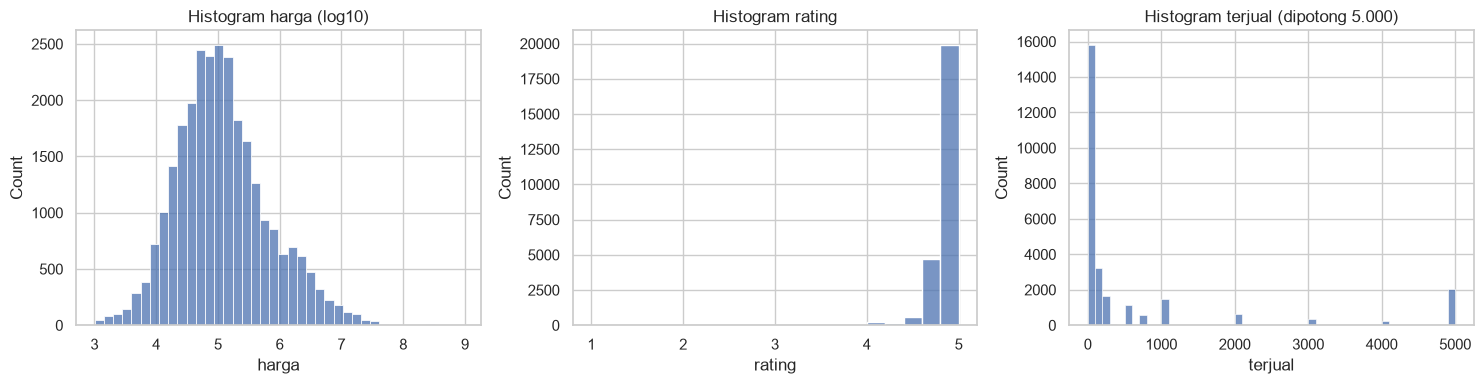

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(np.log10(df["harga"]), bins=40, ax=ax[0])
ax[0].set_title("Histogram harga (log10)")
sns.histplot(df["rating"].dropna(), bins=20, ax=ax[1])
ax[1].set_title("Histogram rating")
sns.histplot(df["terjual"].dropna().clip(upper=5000), bins=50, ax=ax[2])
ax[2].set_title("Histogram terjual (dipotong 5.000)")
plt.tight_layout()
plt.show()

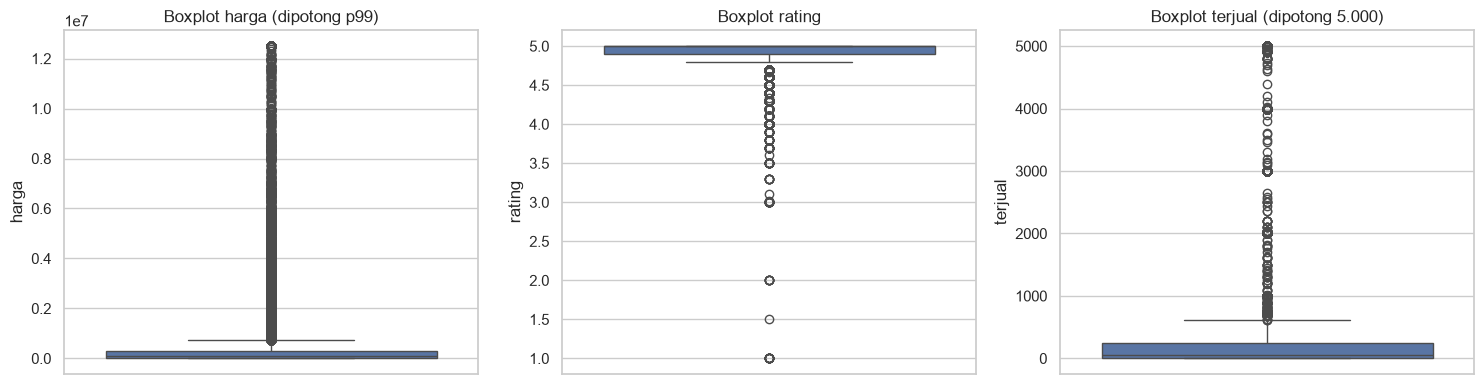

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(y=df["harga"].clip(upper=df["harga"].quantile(0.99)), ax=ax[0])
ax[0].set_title("Boxplot harga (dipotong p99)")
sns.boxplot(y=df["rating"].dropna(), ax=ax[1])
ax[1].set_title("Boxplot rating")
sns.boxplot(y=df["terjual"].dropna().clip(upper=5000), ax=ax[2])
ax[2].set_title("Boxplot terjual (dipotong 5.000)")
plt.tight_layout()
plt.show()

### Univariate - 2. Buat distribusi rating. Apakah menumpuk di 4.5-5.0?

Rating 4,5-5,0: 97.37 %
rating
5.0    14350
4.9     5579
4.8     2940
4.7     1270
4.6      521
Name: count, dtype: int64


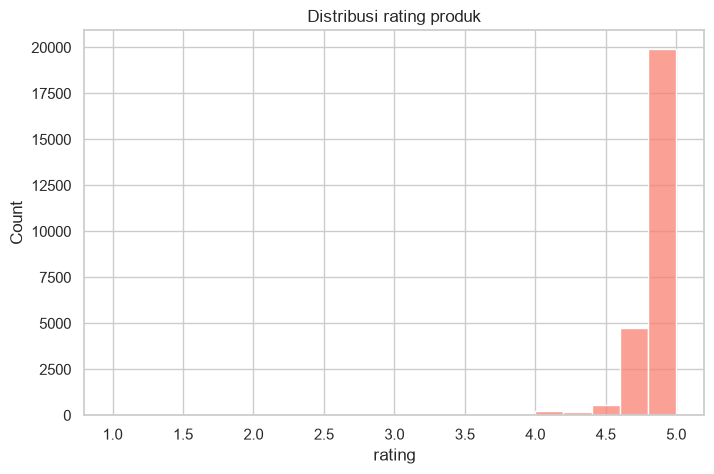

In [22]:
r = df["rating"].dropna()
print("Rating 4,5-5,0:", round((r >= 4.5).mean() * 100, 2), "%")
print(r.value_counts().head(5))
plt.figure(figsize=(8, 5))
sns.histplot(r, bins=20, color="salmon")
plt.title("Distribusi rating produk")
plt.show()

**Rating menumpuk di 4,5–5,0.** Rating hampir tidak membedakan produk.

### Bivariate dan Multivariate - 1. Tampilkan top 10 kategori berdasarkan jumlah listing, total terjual, dan estimasi revenue (harga x terjual). Apakah urutannya sama? Kategori mana yang jenuh (banyak listing, penjualan per listing rendah)?
Hanya 8 kategori yang terbentuk, jadi tabel top 10 menampilkan semua kategori.
Definisi jenuh (buatan kita, bukan dari materi): listing di atas median dan terjual per listing di bawah median.

In [23]:
df["revenue"] = df["harga"] * df["terjual"]
g = df.groupby("kategori").agg(
    listing=("harga", "size"),
    total_terjual=("terjual", "sum"),
    revenue=("revenue", "sum"),
    n_terjual=("terjual", "count"),
)
g["terjual_per_listing"] = (g["total_terjual"] / g["n_terjual"]).round(0)
g.sort_values("listing", ascending=False)

,listing,total_terjual,revenue,n_terjual,terjual_per_listing
kategori,,,,,
Lainnya,18084,35096969,14443740256185,18001,1950.0
Elektronik,2285,2322141,383617656959,2283,1017.0
Pakaian,2127,6608483,421851606527,2105,3139.0
Skincare,1454,12668261,849763686811,1429,8865.0
Olahraga,1004,935081,664720958899,994,941.0
Rumah & Dapur,976,1837721,207461864541,972,1891.0
Bayi & Anak,889,438904,46193441038,882,498.0
Makanan,874,2814131,150766713845,868,3242.0


In [24]:
rank = pd.DataFrame({
    "by_listing": g["listing"].sort_values(ascending=False).index,
    "by_terjual": g["total_terjual"].sort_values(ascending=False).index,
    "by_revenue": g["revenue"].sort_values(ascending=False).index,
})
print("Urutan sama untuk ketiga metrik?", rank.nunique(axis=1).eq(1).all())
rank

Urutan sama untuk ketiga metrik? False


,by_listing,by_terjual,by_revenue
0,Lainnya,Lainnya,Lainnya
1,Elektronik,Skincare,Skincare
2,Pakaian,Pakaian,Olahraga
3,Skincare,Makanan,Pakaian
4,Olahraga,Elektronik,Elektronik
5,Rumah & Dapur,Rumah & Dapur,Rumah & Dapur
6,Bayi & Anak,Olahraga,Makanan
7,Makanan,Bayi & Anak,Bayi & Anak


In [25]:
g["jenuh"] = (g["listing"] >= g["listing"].median()) & (g["terjual_per_listing"] <= g["terjual_per_listing"].median())
g.sort_values("listing", ascending=False)[["listing", "terjual_per_listing", "jenuh"]]

,listing,terjual_per_listing,jenuh
kategori,,,
Lainnya,18084,1950.0,False
Elektronik,2285,1017.0,True
Pakaian,2127,3139.0,False
Skincare,1454,8865.0,False
Olahraga,1004,941.0,False
Rumah & Dapur,976,1891.0,False
Bayi & Anak,889,498.0,False
Makanan,874,3242.0,False


### Bivariate dan Multivariate - 2. Bandingkan jumlah terjual antar segmen harga (murah, menengah, premium; buat sendiri dari kuantil harga) pada tiap kategori. Di segmen mana tiap kategori paling laris?
Segmen dibuat dengan `qcut` 3 kelompok (sama dengan tercile).

In [26]:
df["segmen"] = pd.qcut(df["harga"], 3, labels=["murah", "menengah", "premium"])
print(df["segmen"].value_counts())
print(pd.qcut(df["harga"], 3, retbins=True)[1])

segmen
murah       9236
premium     9231
menengah    9226
Name: count, dtype: int64
[1.01200000e+03 5.22500000e+04 1.98766667e+05 9.00000000e+08]


In [27]:
pt = df.pivot_table(index="kategori", columns="segmen", values="terjual", aggfunc="median", observed=False)
pt["paling_laris"] = pt.idxmax(axis=1)
pt.round(1)

segmen,murah,menengah,premium,paling_laris
kategori,,,,
Bayi & Anak,50.0,30.0,9.0,murah
Elektronik,100.0,60.0,24.0,murah
Lainnya,100.0,50.0,16.0,murah
Makanan,100.0,80.0,30.0,murah
Olahraga,100.0,50.0,18.5,murah
Pakaian,100.0,60.0,14.0,murah
Rumah & Dapur,250.0,80.0,25.0,murah
Skincare,100.0,250.0,80.0,menengah


### Bivariate dan Multivariate - 3. Apakah rating tinggi berhubungan dengan penjualan tinggi?

In [28]:
df["rating_grup"] = np.where(df["rating"] >= 4.5, "rating >= 4.5", np.where(df["rating"].notna(), "rating < 4.5", "kosong"))
df.groupby("rating_grup")["terjual"].agg(["count", "median", "mean"]).round(1)

,count,median,mean
rating_grup,,,
kosong,1801,0.0,27.5
rating < 4.5,677,30.0,943.1
rating >= 4.5,25056,60.0,2475.8


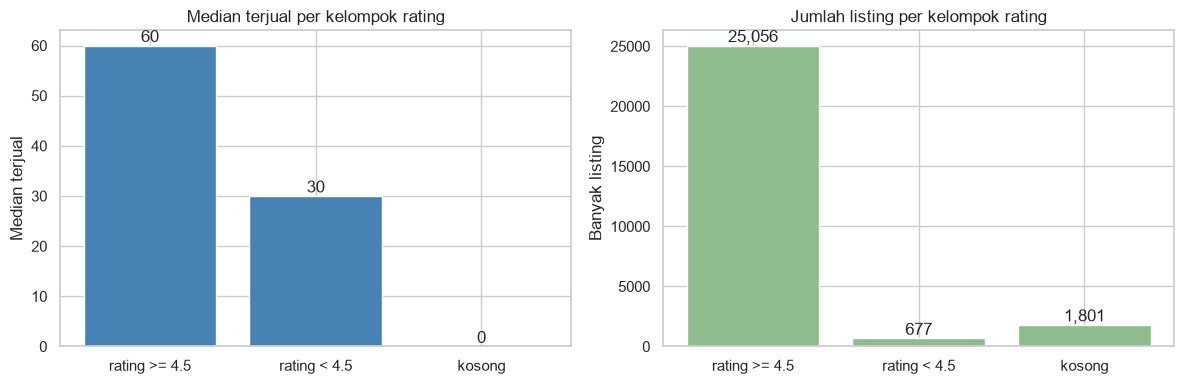

In [29]:
# Visualisasi jawaban: median terjual dan jumlah listing per kelompok rating
urutan = ["rating >= 4.5", "rating < 4.5", "kosong"]
ring = df.groupby("rating_grup")["terjual"].agg(["count", "median", "mean"]).reindex(urutan)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(ring.index, ring["median"], color="steelblue")
ax[0].set_title("Median terjual per kelompok rating")
ax[0].set_ylabel("Median terjual"); ax[0].set_xlabel("")
for i, v in enumerate(ring["median"]):
    ax[0].text(i, v, f"{v:.0f}", ha="center", va="bottom")

ax[1].bar(ring.index, ring["count"], color="darkseagreen")
ax[1].set_title("Jumlah listing per kelompok rating")
ax[1].set_ylabel("Banyak listing"); ax[1].set_xlabel("")
for i, v in enumerate(ring["count"]):
    ax[1].text(i, v, f"{v:,.0f}", ha="center", va="bottom")

for a in ax:
    a.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

**Jawaban: tidak.** Rating tinggi tidak bisa dipakai sebagai penanda penjualan tinggi.- Median terjual kelompok `rating >= 4.5` memang lebih besar (60) daripada `rating < 4.5` (30) dan `kosong` (0). Tapi perbandingan ini lemah: **25.056 dari 25.733 listing yang punya rating (97,4%) sudah berada di 4,5–5,0**, sehingga kelompok pembandingnya hanya 677 listing.- Korelasi Pearson `rating` dan `terjual` hanya **-0,02** (lihat Bivariate dan Multivariate poin 4) — praktis nol.- Kesimpulannya rating di Tokopedia **jenuh di nilai tinggi dan tidak punya daya beda**. Sinyal yang lebih informatif adalah jumlah ulasan (r = 0,51 terhadap terjual).

### Bivariate dan Multivariate - 4. Buat heatmap korelasi untuk variabel numerik. Korelasi mana yang paling kuat dan apa maknanya?

In [30]:
num = df[["harga", "rating", "terjual", "ulasan"]]
corr = num.corr().round(2)
corr

,harga,rating,terjual,ulasan
harga,1.00,0.02,-0.01,-0.01
rating,0.02,1.00,-0.02,-0.02
terjual,-0.01,-0.02,1.00,0.51
ulasan,-0.01,-0.02,0.51,1.00


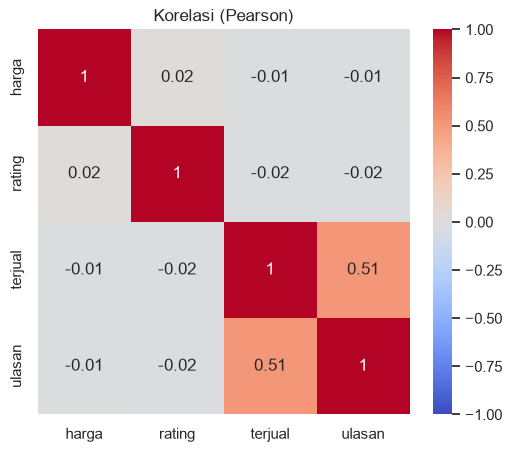

In [31]:
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Korelasi (Pearson)")
plt.show()

Korelasi terkuat: `terjual` dan `ulasan` (r ≈ 0,51, sedang). Lainnya lemah atau hampir nol.

### Geografis - 1. Tampilkan top 10 kota atau provinsi lokasi seller. Seberapa terkonsentrasi seller di Jabodetabek?

In [32]:
print(df["lokasi"].value_counts().head(10))
JABO = "jakarta|bogor|depok|tangerang|bekasi"
jabo = df["lokasi"].str.contains(JABO)
print("Persen listing Jabodetabek:", round(jabo.mean() * 100, 1), "%")
print("Persen terjual Jabodetabek:", round(df.loc[jabo, "terjual"].sum() / df["terjual"].sum() * 100, 1), "%")

lokasi
jakarta            3866
jakarta barat      3000
lainnya            2574
jakarta utara      1755
jakarta pusat      1747
bandung            1448
surabaya           1429
tangerang          1346
jakarta selatan    1037
jakarta timur       996
Name: count, dtype: int64
Persen listing Jabodetabek: 62.8 %
Persen terjual Jabodetabek: 69.1 %


**Konsentrasi seller di Jabodetabek sangat tinggi.**
- Top 10 lokasi didominasi Jakarta dan sekitarnya: `jakarta` 3.866, `jakarta barat` 3.000, `jakarta utara` 1.755, `jakarta pusat` 1.747, `tangerang` 1.346, `jakarta selatan` 1.037, `jakarta timur` 996. Dari luar Jabodetabek hanya `bandung` (1.448) dan `surabaya` (1.429) yang masuk 10 besar.
- **62,8% listing** dan **69,1% volume terjual** berasal dari Jabodetabek.
- Catatan: `lainnya` (2.574 listing) menampung lokasi yang tidak dikenali sebagai kota, jadi angka konsentrasi ini bersifat batas bawah.

### Geografis - 2. Bandingkan median harga, rating, dan terjual berdasarkan lokasi. Apakah seller di luar Jawa berbeda performanya?

In [33]:
JAWA = "jakarta|bogor|depok|tangerang|bekasi|bandung|surabaya|semarang|yogyakarta|solo|malang|cirebon|serang|sukabumi|tegal|magelang|kediri|madiun|jember|pekalongan"
df["jawa"] = df["lokasi"].str.contains(JAWA)
df.groupby("jawa").agg(n=("harga", "size"), med_harga=("harga", "median"),
                       med_rating=("rating", "median"), med_terjual=("terjual", "median")).round(1)

,n,med_harga,med_rating,med_terjual
jawa,,,,
False,5669,96000.0,5.0,25.0
True,22024,99888.0,5.0,60.0


In [34]:
loc = df.groupby("lokasi").agg(n=("harga", "size"), med_terjual=("terjual", "median"))
loc[loc["n"] >= 1000].sort_values("med_terjual", ascending=False)

,n,med_terjual
lokasi,,
jakarta utara,1755,100.0
tangerang,1346,90.0
jakarta barat,3000,90.0
bandung,1448,70.0
jakarta,3866,70.0
jakarta pusat,1747,50.0
jakarta selatan,1037,40.0
surabaya,1429,30.0
lainnya,2574,28.0


**Ya, seller di luar Jawa performanya lebih rendah.**

| Kelompok | n | median harga | median rating | median terjual |
|---|---|---|---|---|
| Jawa | 22.024 | Rp99.888 | 5,0 | **60** |
| Luar Jawa | 5.669 | Rp96.000 | 5,0 | **25** |

- Median terjual seller Jawa **2,4× lebih tinggi** (60 vs 25), padahal median harga dan ratingnya hampir sama. Jadi pembedanya bukan harga atau kualitas, melainkan kedekatan dengan pasar terbesar.
- Per kota (n ≥ 1.000): `jakarta utara` 100, `tangerang` 90, `jakarta barat` 90, `bandung` 70, `jakarta` 70, `jakarta pusat` 50, `jakarta selatan` 40, `surabaya` 30, `lainnya` 28.
- **Batasan:** daftar kota Jawa ditulis manual berdasarkan nama kota besar, jadi pengelompokannya perkiraan. Data juga tidak memuat ongkos atau waktu kirim, sehingga penyebabnya belum bisa dibuktikan.

### Geografis - 3. Cek apakah ada kategori yang didominasi kota tertentu, lalu beri hipotesis penyebabnya.

In [35]:
top6 = df["lokasi"].value_counts().head(6).index
ct = pd.crosstab(df["kategori"], df["lokasi"].where(df["lokasi"].isin(top6), "lainnya"), normalize="index").round(2)
ct

lokasi,bandung,jakarta,jakarta barat,jakarta pusat,jakarta utara,lainnya
kategori,,,,,,
Bayi & Anak,0.04,0.20,0.10,0.04,0.08,0.54
Elektronik,0.05,0.21,0.13,0.14,0.08,0.39
Lainnya,0.05,0.13,0.11,0.06,0.06,0.59
Makanan,0.05,0.11,0.11,0.05,0.07,0.61
Olahraga,0.06,0.14,0.08,0.04,0.05,0.62
Pakaian,0.10,0.09,0.11,0.05,0.05,0.61
Rumah & Dapur,0.05,0.13,0.12,0.05,0.07,0.57
Skincare,0.04,0.21,0.10,0.03,0.06,0.55


**Hipotesis penyebab pola geografis (belum diuji).**
- Skincare dan Elektronik paling banyak di Jakarta (sekitar 0,21 per baris kategori). Pakaian paling banyak di Bandung (0,15).
- Hipotesis: Skincare dan Elektronik berkumpul di Jakarta karena pusat distribusi dan kantor brand. Pakaian di Bandung karena sentra produksi.
- Data ini tidak punya informasi distribusi atau produksi, jadi belum bisa dibuktikan. Perlu data tambahan.
- Rumah & Dapur dan Olahraga banyak di `lainnya` (sekitar 0,5), jadi pola lokasinya tidak jelas.

## Bagian 4: Insight dan Rekomendasi
### 4.1 Rangkum 5 temuan utama dalam bahasa non-teknis.

1. **Kategori terbesar tidak otomatis paling laku.** Elektronik punya listing terbanyak di antara kategori yang terklasifikasi (2.285), tapi penjualan per listing hanya 1.017 dan masuk kategori **jenuh**. Skincare cuma 1.454 listing, tapi penjualan per listing 8.865 — paling tinggi (lihat Bivariate dan Multivariate poin 1). Karena 65,3% listing masuk `Lainnya`, temuan per kategori hanya berlaku untuk bagian yang terklasifikasi.
2. **Segmen murah paling laku di hampir semua kategori.** Median terjual segmen murah tertinggi di 7 dari 8 kategori. Skincare satu-satunya pengecualian: tertinggi di segmen menengah (250), lalu murah (100) dan premium (80) (lihat Bivariate dan Multivariate poin 2).
3. **Rating tidak bisa dipakai membedakan produk.** 97,4% listing yang punya rating ada di 4,5–5,0, dan korelasinya dengan penjualan praktis nol (r = -0,02) (lihat Bivariate dan Multivariate poin 3).
4. **Jumlah ulasan adalah sinyal terkuat.** Korelasinya dengan penjualan r = 0,51 (sedang), jauh di atas harga (r = -0,01) maupun rating (r = -0,02). Ini hubungan, bukan sebab-akibat (lihat Bivariate dan Multivariate poin 4).
5. **Seller menumpuk di Jabodetabek.** 62,8% listing dan 69,1% volume terjual berasal dari sana (lihat Geografis poin 1). Median terjual seller Jawa 60, luar Jawa 25 (lihat Geografis poin 2). Daftar kota Jawa dibuat manual, jadi ini perkiraan.

### 4.2 Berikan 3 rekomendasi spesifik untuk brand tersebut (kategori, rentang harga, strategi lokasi gudang atau seller), masing-masing didukung angka dari EDA.

1. **Fokus Skincare di segmen menengah.** Penjualan per listing tertinggi (8.865) dan satu-satunya kategori yang paling laris di segmen menengah (median terjual 250, dibanding murah 100 dan premium 80). Jumlah listing-nya hanya 1.454 — jauh di bawah `Lainnya` (18.084) dan Elektronik (2.285), jadi permintaan tinggi dengan persaingan relatif longgar (lihat Bivariate dan Multivariate poin 1 & 2).
2. **Untuk kategori selain Skincare, main di harga murah.** Median terjual segmen murah tertinggi di 7 dari 8 kategori, rentangnya 50–250 (umumnya 100), di atas segmen menengah (30–80) dan premium (9–30). Segmen premium hanya masuk akal kalau brand sudah kuat (lihat Bivariate dan Multivariate poin 2).
3. **Mulai dari seller atau gudang di Jabodetabek.** 62,8% listing dan 69,1% volume terjual berasal dari sana. Median terjual `jakarta utara` 100, `tangerang` 90, dan `jakarta barat` 90 — di atas `surabaya` 30 dan luar Jawa 25 (lihat Geografis poin 1 & 2). Ini masih hipotesis, karena data tidak memuat waktu atau ongkos pengiriman.

## Batasan data
- Satu baris = satu listing, bukan transaksi. Tidak ada kolom tanggal, jadi tidak ada analisis tren.
- `Terjual` berupa rentang (`1rb+`, `250+`), sehingga nilainya perkiraan batas bawah, bukan angka pasti.
- Kategori diturunkan dari kata kunci di `Nama Produk`. Setelah cleaning, 65,3% listing masuk `Lainnya`, jadi temuan per kategori hanya berlaku untuk bagian yang terklasifikasi.
- Tidak ada kolom stok, sehingga cek "stok negatif" pada poin 2.7 tidak bisa dilakukan.
- Harga ekstrem (sampai Rp900 juta) masih ada di data bersih. Rata-rata dan varians terpengaruh, maka median lebih aman dibaca.
- Daftar kota Jawa dan definisi Jabodetabek ditulis manual dari nama lokasi, jadi pengelompokan geografisnya perkiraan.